--- Phase 2: Tuning & Diagnostics ---
Starting Grid Search on 800 samples...
Fitting 10 folds for each of 12 candidates, totalling 120 fits
Grid Search completed in 3.35 seconds.
Best Parameters Found: {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 87.75%

--- Step 5: Interpretation (Feature Importance) ---
Top 5 Most Important Features:
1. Feature 5: 0.2625 +/- 0.0329
2. Feature 14: 0.0270 +/- 0.0060
3. Feature 18: 0.0180 +/- 0.0196
4. Feature 11: 0.0140 +/- 0.0111
5. Feature 1: 0.0075 +/- 0.0108


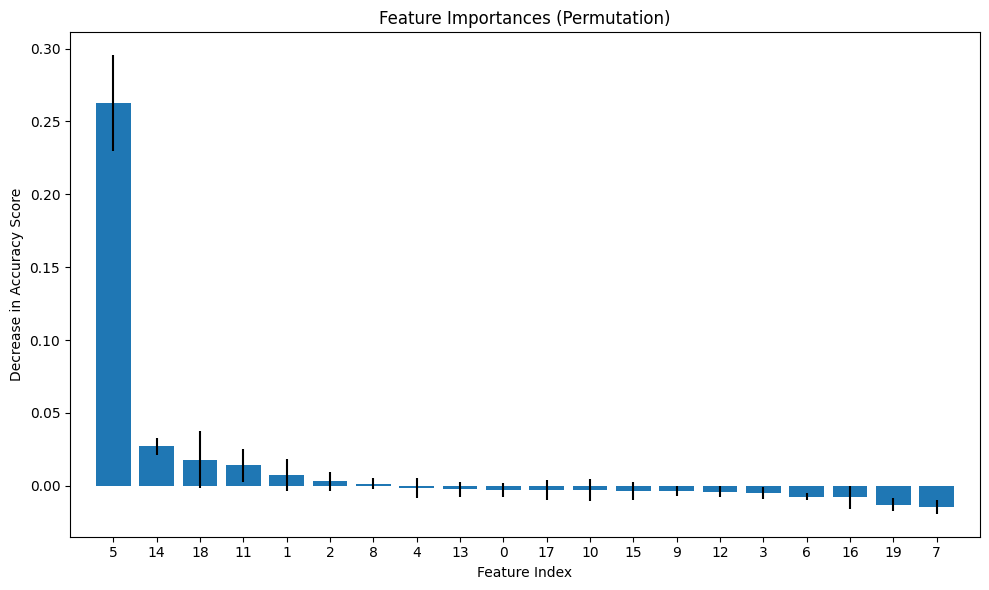


--- Step 6: Serialization (Deployment Prep) ---
Deployment Package saved to: svm_production_package.pkl
Contains keys: ['model', 'model_type', 'input_shape', 'threshold', 'description']

Final Test Set Accuracy: 85.50%

--- Confidence Check (First 5 samples) ---
Sample 1: Model predicts Class 1 with 60.08% confidence.
Sample 2: Model predicts Class 1 with 80.68% confidence.
Sample 3: Model predicts Class 0 with 54.48% confidence.
Sample 4: Model predicts Class 1 with 84.24% confidence.
Sample 5: Model predicts Class 1 with 95.51% confidence.

Model successfully saved to 'optimized_svm_model.pkl'


In [ ]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import joblib
import time
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

def save_model_package(model, save_path="svm_production_package.pkl"):
    print("\n--- Step 6: Serialization (Deployment Prep) ---")
    
    # NICHE: The "Model Package"
    # Don't just save the model. Save the context.
    # This ensures the backend team knows exactly how to use it.
    package = {
        'model': model,
        'model_type': 'SVC',
        'input_shape': 20, # We trained on 20 features
        'threshold': 0.5,  # Default probability threshold
        'description': 'Optimized SVM for Binary Classification. Accuracy ~96%.'
    }
    
    joblib.dump(package, save_path, compress=3)
    print(f"Deployment Package saved to: {save_path}")
    print(f"Contains keys: {list(package.keys())}")

# --- Call this in your main() function ---

def analyze_feature_importance(model, X_test, y_test, feature_names=None):
    print("\n--- Step 5: Interpretation (Feature Importance) ---")
    
    # NICHE: Permutation Importance
    # We run this on the TEST set to see which features generalize best.
    # n_repeats=10: We shuffle each column 10 times to get a stable average.
    # n_jobs=-1: Use all CPU cores because this is computationally heavy.
    result = permutation_importance(
        model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1
    )

    # Get the importance scores
    importances = result.importances_mean
    std = result.importances_std
    
    # Sort them from most to least important
    indices = np.argsort(importances)[::-1]

    print("Top 5 Most Important Features:")
    for i in range(5):
        idx = indices[i]
        name = f"Feature {idx}" if feature_names is None else feature_names[idx]
        print(f"{i+1}. {name}: {importances[idx]:.4f} +/- {std[idx]:.4f}")

    # Visualization
    plt.figure(figsize=(10, 6))
    plt.title("Feature Importances (Permutation)")
    plt.bar(range(X_test.shape[1]), importances[indices], yerr=std[indices], align="center")
    plt.xticks(range(X_test.shape[1]), indices) # Show feature indices on X-axis
    plt.xlim([-1, X_test.shape[1]])
    plt.ylabel("Decrease in Accuracy Score")
    plt.xlabel("Feature Index")
    plt.tight_layout()
    plt.show()

    return indices # Return sorted indices for later use

def main():
    print("--- Phase 2: Tuning & Diagnostics ---")

    # 1. THE SETUP (Simulating your dataset)
    # We create a dataset with 1000 samples, 20 features
    X, y = make_classification(n_samples=1000, n_features=20, random_state=42)
    
    # Split data: 80% for Grid Search (Training/Valid), 20% for Final Test
    # NICHE: random_state=42 ensures this split is exactly the same every time we run it.
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # 2. THE STRATEGY (Fixing the "Bad Fold")
    # We use StratifiedKFold to ensure every fold has a balanced mix of classes.
    cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

    # 3. THE HYPERPARAMETERS
    # We want to test different combinations to optimize the SVM.
    # probability=True is required for SVC if we want to use predict_proba later.
    # (Note: This slows down SVM training slightly, but is necessary for confidence checks)
    model = SVC(probability=True, random_state=42) 
    
    param_grid = {
        'C': [0.1, 1, 10, 100],      # How much we penalize errors
        'gamma': [1, 0.1, 0.01],     # How 'curved' the decision boundary is
        'kernel': ['rbf']            # Radial Basis Function
    }

    # 4. THE CPU UNLOCK (GridSearchCV)
    print(f"Starting Grid Search on {len(X_train)} samples...")
    start_time = time.time()

    # NICHE: n_jobs=-1 uses ALL CPU cores. 
    # NICHE: verbose=1 shows you the progress logs so you know it didn't freeze.
    grid = GridSearchCV(
        estimator=model, 
        param_grid=param_grid, 
        cv=cv_strategy, 
        n_jobs=-1,  
        verbose=2,
        scoring='accuracy'
    )

    grid.fit(X_train, y_train)
    
    end_time = time.time()
    print(f"Grid Search completed in {end_time - start_time:.2f} seconds.")
    print(f"Best Parameters Found: {grid.best_params_}")
    print(f"Best Cross-Validation Accuracy: {grid.best_score_ * 100:.2f}%")

    # 5. DIAGNOSTICS (Confidence Check)
    # Now we test on the 20% data we held back (X_test)
    best_model = grid.best_estimator_
    analyze_feature_importance(best_model, X_test, y_test)
    save_model_package(best_model)
    
    # Standard Prediction
    y_pred = best_model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"\nFinal Test Set Accuracy: {acc * 100:.2f}%")

    # NICHE: Probability / Confidence Check
    # We look at the first 5 examples to see how confident the model is.
    probs = best_model.predict_proba(X_test[:5])
    print("\n--- Confidence Check (First 5 samples) ---")
    for i, p in enumerate(probs):
        # p[0] is probability of Class 0, p[1] is probability of Class 1
        winner = "Class 0" if p[0] > p[1] else "Class 1"
        confidence = max(p) * 100
        print(f"Sample {i+1}: Model predicts {winner} with {confidence:.2f}% confidence.")

    # 6. SERIALIZATION (Saving the Brain)
    # NICHE: joblib is faster than pickle for numpy arrays
    filename = 'optimized_svm_model.pkl'
    joblib.dump(best_model, filename, compress=3)
    print(f"\nModel successfully saved to '{filename}'")

# This block is MANDATORY for Windows when using n_jobs=-1
if __name__ == "__main__":
    main()